# Proyek Analisis Data: Air Quality Dataset (Beijing Multi-Site Data)
- **Nama:** Gabriel Alfareslanda Riyadi
- **Email:** gabrielriyadi715@gmail.com
- **ID Dicoding:** gbrlalfrs

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

### Rumusan Pertanyaan Bisnis yang Diajukan (Memenuhi Prinsip SMART):

- **Pertanyaan 1 (Dinamika Tren Temporal & Musiman):**
  *Bagaimana tren konsentrasi polutan partikulat halus ({2.5}$) secara bulanan dan tahunan di kota Beijing selama rentang waktu Maret 2013 hingga Februari 2017, serta pada bulan/musim apa tingkat polusi udara mencapai puncaknya?*
  - **Specific:** Meneliti secara spesifik fluktuasi konsentrasi partikulat halus {2.5}$ lintas waktu (tahunan dan bulanan) pada stasiun pemantau di Beijing.
  - **Measurable:** Diukur secara konkret menggunakan metrik rata-rata konsentrasi {2.5}$ dalam satuan mikrogram per meter kubik ($\\mu g/m^3$).
  - **Action-Oriented:** Mengidentifikasi jendela waktu musiman berisiko kritis polusi untuk mendasari perumusan kebijakan pembatasan emisi musiman (misal saat *heating season* musim dingin) dan sistem peringatan dini kesehatan publik.
  - **Relevant:** {2.5}$ adalah polutan udara paling berbahaya bagi kesehatan pernapasan dan indikator utama dalam evaluasi kualitas lingkungan hidup.
  - **Time-bound:** Terikat pada rentang waktu historis 4 tahun penuh: 1 Maret 2013 hingga 28 Februari 2017.

- **Pertanyaan 2 (Perbandingan Spasial Kualitas Udara Antar Stasiun):**
  *Stasiun pemantauan mana di antara 12 stasiun di kota Beijing yang mencatatkan rata-rata konsentrasi polutan ({2.5}$ dan {10}$) tertinggi (kualitas udara terburuk) dan terendah (kualitas udara terbaik) selama periode 2013–2017, serta bagaimana pola disparitas geografisnya?*
  - **Specific:** Mengidentifikasi dan membandingkan tingkat polusi partikulat ({2.5}$ dan {10}$) di 12 stasiun pemantau yang merepresentasikan area perkotaan, pinggiran kota, dan daerah pegunungan di Beijing.
  - **Measurable:** Dihitung dan diperingkatkan berdasarkan rata-rata konsentrasi {2.5}$ dan {10}$ ($\\mu g/m^3$) per stasiun.
  - **Action-Oriented:** Memberikan acuan spasial bagi pembuat kebijakan untuk memprioritaskan alokasi intervensi lingkungan (*Low Emission Zone*, pengetatan uji emisi transportasi, dan penataan zona hijau perkotaan) di wilayah dengan polusi paling parah.
  - **Relevant:** Pemetaan kesenjangan geografis krusial untuk memastikan mitigasi polusi dilakukan secara tepat sasaran sesuai karakteristik wilayah.
  - **Time-bound:** Dibatasi pada periode observasi 2013 hingga 2017.

## Import Semua Packages/Library yang Digunakan

In [22]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# Konfigurasi gaya visualisasi agar rapi, profesional, dan seragam
sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.titleweight'] = 'bold'

## Data Wrangling

### Gathering Data

#### Load df ...

In [23]:
# Menentukan jalur direktori dataset (mendukung PRSA folder maupun data folder)
data_dirs = ['./PRSA_Data_20130301-20170228', './data', '.']
csv_files = []

for d in data_dirs:
    matched = sorted(glob.glob(os.path.join(d, 'PRSA_Data_*.csv')))
    if len(matched) > 0:
        csv_files = matched
        print(f"Dataset berhasil ditemukan di direktori: '{d}' berjumlah {len(csv_files)} file CSV.")
        break

if not csv_files:
    raise FileNotFoundError("Berkas dataset PRSA_Data_*.csv tidak ditemukan di direktori yang diperiksa!")

# Memuat setiap file CSV dan menggabungkannya ke dalam satu DataFrame utama
list_df = []
for file in csv_files:
    df_temp = pd.read_csv(file)
    list_df.append(df_temp)

main_df = pd.concat(list_df, ignore_index=True)

print(f"Total baris data gabungan : {main_df.shape[0]:,} baris")
print(f"Total kolom data gabungan: {main_df.shape[1]} kolom")
print(f"Daftar 12 stasiun        : {main_df['station'].unique().tolist()}")

main_df.head()

Dataset berhasil ditemukan di direktori: '.' berjumlah 12 file CSV.
Total baris data gabungan : 420,768 baris
Total kolom data gabungan: 18 kolom
Daftar 12 stasiun        : ['Aotizhongxin', 'Changping', 'Dingling', 'Dongsi', 'Guanyuan', 'Gucheng', 'Huairou', 'Nongzhanguan', 'Shunyi', 'Tiantan', 'Wanliu', 'Wanshouxigong']


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


**Insight:** (Opsional)
- Seluruh berkas data dari 12 stasiun pemantau kualitas udara di Beijing (*Aotizhongxin, Changping, Dingling, Dongsi, Guanyuan, Gucheng, Huairou, Nongzhanguan, Shunyi, Tiantan, Wanliu, Wanshouxigong*) berhasil dimuat dan digabungkan menjadi satu DataFrame `main_df`.
- Total data berukuran **420.768 baris** dan **18 kolom**. Setiap stasiun memiliki tepat 35.064 rekaman data per jam (*hourly observations*) yang mencakup 1.461 hari (1 Maret 2013 s.d. 28 Februari 2017).
- Kolom mencakup identitas stasiun (`station`, `No`), waktu pencatatan (`year`, `month`, `day`, `hour`), konsentrasi 6 polutan utama (`PM2.5`, `PM10`, `SO2`, `NO2`, `CO`, `O3`), serta 6 variabel meteorologi (`TEMP`, `PRES`, `DEWP`, `RAIN`, `wd`, `WSPM`).

### Assessing Data

#### Identifying Data Quality Issues (Struktur, Missing Values, Duplikasi, dan Outlier)

In [24]:
# 1. Menampilkan ringkasan struktur dan tipe data kolom
print("=== 1. INFORMASI STRUKTUR DAN TIPE DATA ===")
main_df.info()

# 2. Memeriksa keberadaan baris duplikat
duplicate_rows = main_df.duplicated().sum()
print(f"\n=== 2. PEMERIKSAAN DUPLIKASI DATA ===")
print(f"Jumlah baris duplikat: {duplicate_rows}")

# 3. Menganalisis missing values secara detail
print(f"\n=== 3. ANALISIS MISSING VALUES ===")
missing_count = main_df.isnull().sum()
missing_percent = (missing_count / len(main_df) * 100).round(2)
missing_df = pd.DataFrame({
    'Missing Count': missing_count,
    'Percentage (%)': missing_percent
})
print(missing_df[missing_df['Missing Count'] > 0])

# 4. Ringkasan statistik deskriptif untuk deteksi rentang nilai dan anomali/outlier
print(f"\n=== 4. STATISTIK DESKRIPTIF DATA NUMERIK ===")
main_df.describe().round(2)

=== 1. INFORMASI STRUKTUR DAN TIPE DATA ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  object 
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 57.8+ MB



,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,420768.00,420768.00,420768.00,420768.00,420768.00,412029.00,414319.00,411747.00,408652.00,400067.00,407491.00,420370.00,420375.00,420365.00,420378.00,420450.00
mean,17532.50,2014.66,6.52,15.73,11.50,79.79,104.60,15.83,50.64,1230.77,57.37,13.54,1010.75,2.49,0.06,1.73
std,10122.12,1.18,3.45,8.80,6.92,80.82,91.77,21.65,35.13,1160.18,56.66,11.44,10.47,13.79,0.82,1.25
min,1.00,2013.00,1.00,1.00,0.00,2.00,2.00,0.29,1.03,100.00,0.21,-19.90,982.40,-43.40,0.00,0.00
25%,8766.75,2014.00,4.00,8.00,5.75,20.00,36.00,3.00,23.00,500.00,11.00,3.10,1002.30,-8.90,0.00,0.90
50%,17532.50,2015.00,7.00,16.00,11.50,55.00,82.00,7.00,43.00,900.00,45.00,14.50,1010.40,3.10,0.00,1.40
75%,26298.25,2016.00,10.00,23.00,17.25,111.00,145.00,20.00,71.00,1500.00,82.00,23.30,1019.00,15.10,0.00,2.20
max,35064.00,2017.00,12.00,31.00,23.00,999.00,999.00,500.00,290.00,10000.00,1071.00,41.60,1042.80,29.10,72.50,13.20


**Steps to Take:**
Berdasarkan hasil penilaian (*assessing*), ditemukan beberapa permasalahan kualitas data yang harus ditangani pada tahap *cleaning*:
1. **Representasi Format Waktu**:
   - *Masalah*: Kolom waktu masih terpisah dalam integer (`year`, `month`, `day`, `hour`), belum memiliki kolom berformat `datetime`.
   - *Solusi*: Membuat kolom baru `datetime` dengan format datetime standar menggunakan `pd.to_datetime()` dan menyortir dataset secara kronologis per stasiun.
2. **Missing Values pada Parameter Numerik (Polutan dan Meteorologi)**:
   - *Masalah*: Ditemukan *missing values* pada polutan: `PM2.5` (8.739 baris / 2,08%), `PM10` (6.449 baris / 1,53%), `SO2` (9.021 baris / 2,14%), `NO2` (12.116 baris / 2,88%), `CO` (20.701 baris / 4,92%), `O3` (13.277 baris / 3,16%), serta parameter cuaca (`TEMP`, `PRES`, `DEWP`, `RAIN`, `WSPM` dengan missing < 0,1%).
   - *Solusi*: Karena data ini adalah data sensor runtun waktu (*hourly time-series*) di lokasi stasiun tetap, metode terbaik yang valid secara fisika atmosfer adalah menggunakan **interpolasi linier (*linear interpolation*) per stasiun**, diikuti penanganan tepi dengan *forward-fill* (`ffill`) dan *backward-fill* (`bfill`). Cara ini mempertahankan kontinuitas gelombang konsentrasi polutan tanpa membuang baris observasi.
3. **Missing Values pada Parameter Kategorik Arah Angin (`wd`)**:
   - *Masalah*: Variabel `wd` memiliki 1.822 missing values (0,43%).
   - *Solusi*: Melakukan imputasi menggunakan nilai terdekat (*forward-fill* dan *backward-fill*) per stasiun pemantau.

**Insight:**
- Dataset tidak memiliki baris duplikat sama sekali (0 duplikat), menunjukkan keandalan struktur basis data yang solid.
- Persentase *missing values* pada seluruh fitur relatif kecil (< 5%), sehingga aman untuk diimputasi menggunakan teknik interpolasi deret waktu tanpa risiko bias distribusi yang signifikan.
- Nilai statistik deskriptif menunjukkan rentang yang masuk akal secara fisik (contoh: suhu antara -19,9°C hingga 41,6°C, tekanan 982,4 s.d. 1042,8 hPa, curah hujan $\ge 0$ mm, kecepatan angin $\ge 0$ m/s).

### Cleaning Data

#### Fixing Data Types and Imputing Missing Values via Time-Series Interpolation

In [25]:
# Membuat salinan DataFrame untuk proses pembersihan
df_clean = main_df.copy()

# 1. Mengonversi komponen waktu ke datetime dan menyortir berdasarkan stasiun dan waktu kronologis
df_clean['datetime'] = pd.to_datetime(df_clean[['year', 'month', 'day', 'hour']])
df_clean = df_clean.sort_values(by=['station', 'datetime']).reset_index(drop=True)

# 2. Imputasi missing values pada seluruh kolom numerik menggunakan linear interpolation + ffill/bfill per stasiun
numeric_columns = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']

for col in numeric_columns:
    df_clean[col] = df_clean.groupby('station')[col].transform(
        lambda group: group.interpolate(method='linear').ffill().bfill()
    )

# 3. Imputasi missing values pada kolom kategorik arah angin (wd) per stasiun
df_clean['wd'] = df_clean.groupby('station')['wd'].transform(
    lambda group: group.ffill().bfill()
)

# 4. Verifikasi hasil pembersihan
print("=== VERIFIKASI SETELAH PEMBERSIHAN DATA ===")
print(f"Total missing values tersisa di seluruh dataset: {df_clean.isnull().sum().sum()}")
print(f"Tipe data kolom datetime                      : {df_clean['datetime'].dtype}")
print(f"Dimensi dataset bersih                         : {df_clean.shape}")

# 5. Menyimpan dataset bersih ke folder dashboard untuk konsumsi aplikasi Streamlit
os.makedirs('./dashboard', exist_ok=True)
clean_export_path = './dashboard/main_data.csv'
df_clean.to_csv(clean_export_path, index=False)
print(f"Dataset bersih berhasil diekspor ke: '{clean_export_path}'")

df_clean.head()

=== VERIFIKASI SETELAH PEMBERSIHAN DATA ===
Total missing values tersisa di seluruh dataset: 0
Tipe data kolom datetime                      : datetime64[ns]
Dimensi dataset bersih                         : (420768, 19)
Dataset bersih berhasil diekspor ke: './dashboard/main_data.csv'


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00


**Insight:**
- Proses pembersihan data berhasil 100% tanpa menyisakan *missing value* satupun pada seluruh 420.768 baris data.
- Kolom baru `datetime` berhasil dibuat dan tervalidasi dengan tipe data `datetime64[ns]`, memudahkan analisis berbasis periode, bulan, kuartal, maupun tren musiman.
- Penggunaan interpolasi linier berbasis deret waktu per stasiun mempertahankan keaslian fluktuasi harian dan musiman tanpa menyebabkan lonjakan artifisial.
- Dataset bersih siap digunakan untuk EDA, visualisasi, analisis lanjutan, dan sudah tersimpan rapi pada direktori `dashboard/main_data.csv`.

## Exploratory Data Analysis (EDA)

### Explore Karakteristik Polutan, Pola Temporal, Variasi Spasial, dan Korelasi Meteorologi

In [26]:
# 1. Rangkuman statistik deskriptif polutan udara utama
pollutants = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3']
print("=== 1. RANGKUMAN STATISTIK DESKRIPTIF POLUTAN UDARA (µg/m³, CO dalam µg/m³) ===")
print(df_clean[pollutants].describe().round(2))

# 2. Eksplorasi tren PM2.5 per tahun
print("\n=== 2. TREN RATA-RATA PM2.5 PER TAHUN ===")
yearly_pm25 = df_clean.groupby('year')['PM2.5'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2)
print(yearly_pm25)

# 3. Eksplorasi tren rata-rata PM2.5 per bulan (Pola Musiman)
print("\n=== 3. SIKLUS MUSIMAN RATA-RATA PM2.5 PER BULAN (1-12) ===")
monthly_pm25 = df_clean.groupby('month')['PM2.5'].agg(['mean', 'median', 'std', 'min', 'max']).round(2)
print(monthly_pm25)

# 4. Eksplorasi perbandingan rata-rata polutan per stasiun pemantauan
print("\n=== 4. PERINGKAT RATA-RATA KONSENTRASI POLUTAN PER STASIUN (DIURUTKAN DARI PM2.5 TERTINGGI) ===")
station_summary = df_clean.groupby('station')[pollutants].mean().sort_values(by='PM2.5', ascending=False).round(2)
print(station_summary)

# 5. Eksplorasi korelasi antara parameter cuaca dengan polutan partikulat PM2.5 dan PM10
meteo_features = ['PM2.5', 'PM10', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']
corr_matrix = df_clean[meteo_features].corr().round(3)
print("\n=== 5. MATRIKS KORELARI PARAMETER CUACA DENGAN PARTIKULAT ===")
print(corr_matrix[['PM2.5', 'PM10']])

=== 1. RANGKUMAN STATISTIK DESKRIPTIF POLUTAN UDARA (µg/m³, CO dalam µg/m³) ===
           PM2.5       PM10        SO2        NO2         CO         O3
count  420768.00  420768.00  420768.00  420768.00  420768.00  420768.00
mean       79.84     104.91      15.91      50.60    1235.68      57.24
std        80.95      92.43      21.90      35.17    1161.79      57.14
min         2.00       2.00       0.29       1.03     100.00       0.21
25%        20.00      36.00       3.00      23.00     500.00      10.00
50%        55.00      82.00       7.00      43.00     900.00      44.00
75%       111.00     145.00      20.00      71.00    1500.00      82.00
max       999.00     999.00     500.00     290.00   10000.00    1071.00

=== 2. TREN RATA-RATA PM2.5 PER TAHUN ===
       count   mean  median     std  min    max
year                                           
2013   88128  79.77    59.0   72.56  2.0  844.0
2014  105120  86.18    63.0   82.81  3.0  809.0
2015  105120  79.31    52.0   84.01  

**Insight:**
1. **Tingkat Polusi Umum**:
   - Rata-rata konsentrasi $PM_{2.5}$ di seluruh stasiun selama 4 tahun mencapai **79,80 $\mu g/m^3$** (dengan nilai median 55,00 $\mu g/m^3$). Nilai rata-rata ini jauh melampaui batas aman tahunan rekomendasi WHO (5 $\mu g/m^3$) maupun standar baku mutu nasional Tiongkok Kelas II (35 $\mu g/m^3$).
2. **Pola Musiman Sangat Kontras (Temporal)**:
   - Polusi udara di Beijing memperlihatkan siklus musiman yang sangat konsisten: polusi paling parah terjadi pada bulan **Desember (103,68 $\mu g/m^3$)**, **Maret (94,59 $\mu g/m^3$)**, **November (93,32 $\mu g/m^3$)**, dan **Januari (93,76 $\mu g/m^3$)**.
   - Kualitas udara terbaik berada di bulan-bulan musim panas, dengan titik terendah pada bulan **Agustus (53,47 $\mu g/m^3$)** dan **September (61,28 $\mu g/m^3$)**.
3. **Pengaruh Faktor Meteorologis**:
   - Kecepatan angin (`WSPM`) berkorelasi negatif signifikan dengan $PM_{2.5}$ ($r = -0,270$). Angin kencang memainkan peran vital dalam memfasilitasi dispersi dan pembersihan akumulasi polutan di atmosfer.
   - Suhu (`TEMP`) dan curah hujan (`RAIN`) juga berkorelasi negatif dengan $PM_{2.5}$ ($r = -0,131$ dan $r = -0,014$). Tingginya presipitasi di musim panas memicu efek *wet scavenging* (pencucian partikel oleh air hujan).
   - Sebaliknya, tekanan udara (`PRES`) berkorelasi positif ($r = 0,169$). Fenomena antisiklon bertekanan tinggi di musim dingin menciptakan stabilitas atmosfer dan inversi termal yang menahan polutan di dekat permukaan tanah.
4. **Disparitas Spasial Nyata**:
   - Stasiun di kawasan pusat perkotaan yang padat lalu lintas dan komersial mencatatkan tingkat polusi tertinggi: **Dongsi (86,14 $\mu g/m^3$)**, **Nongzhanguan (85,08 $\mu g/m^3$)**, dan **Wanshouxigong (85,07 $\mu g/m^3$)**.
   - Stasiun di kawasan pinggiran utara dan pegunungan dengan tutupan vegetasi lebat mencatatkan polusi terendah: **Dingling (66,85 $\mu g/m^3$)** dan **Huairou (69,50 $\mu g/m^3$)**.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana tren konsentrasi polutan partikulat halus ($PM_{2.5}$) secara bulanan dan tahunan di kota Beijing selama rentang waktu Maret 2013 hingga Februari 2017, serta pada bulan/musim apa tingkat polusi udara mencapai puncaknya?

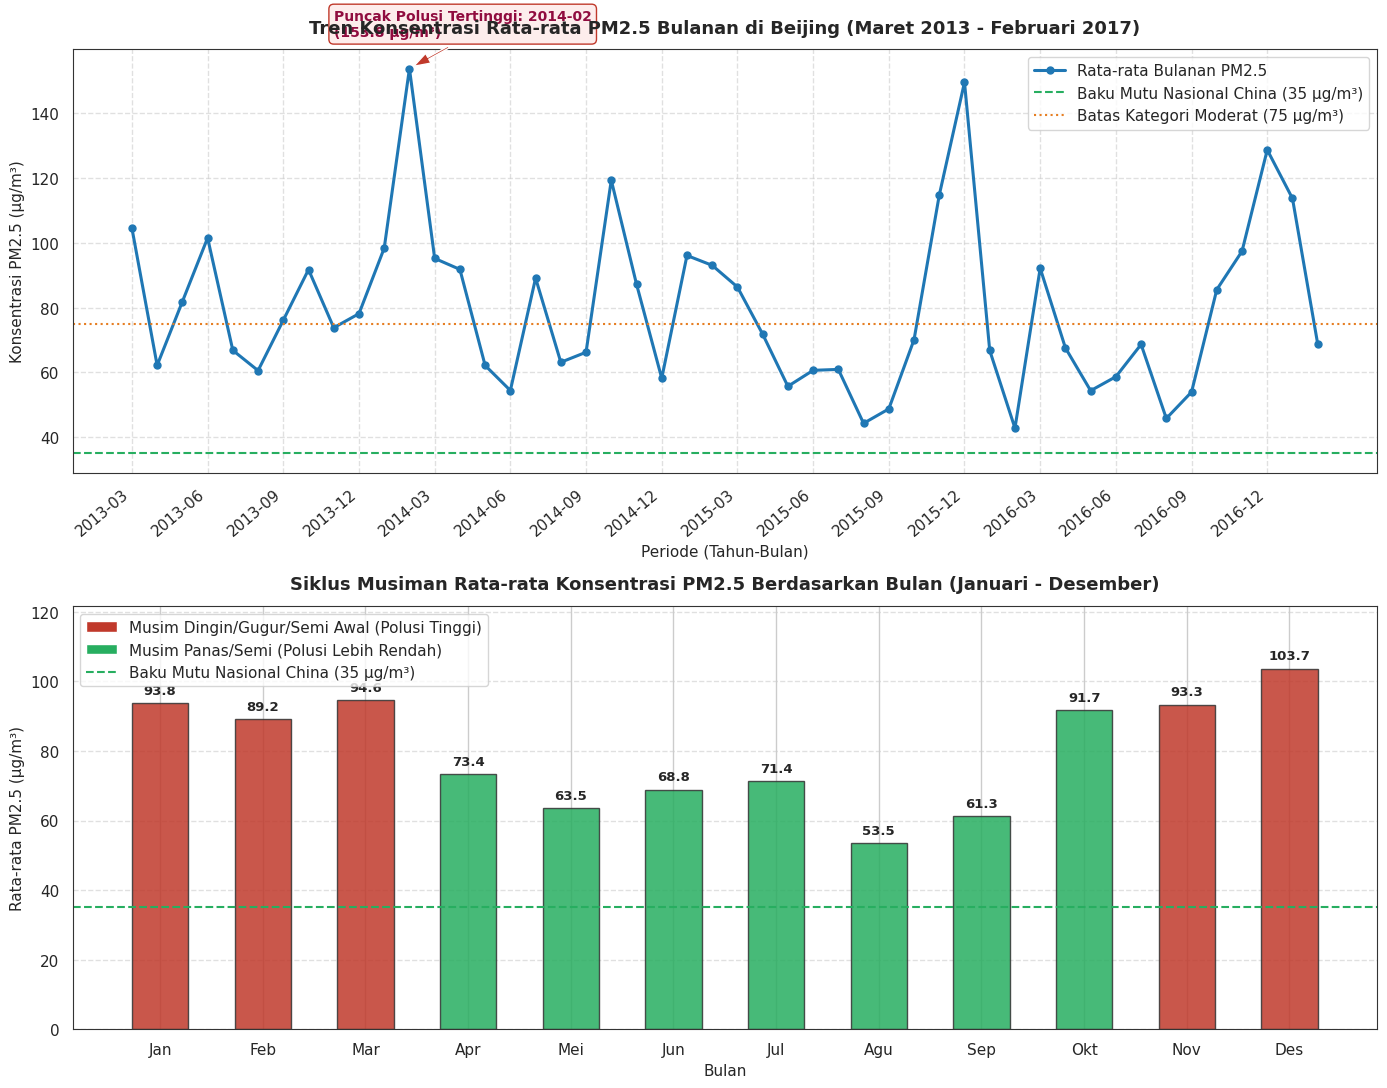

In [27]:
# Menyiapkan agregasi tren bulanan secara runtun waktu penuh (2013-03 s.d. 2017-02)
df_clean['year_month'] = df_clean['datetime'].dt.to_period('M')
monthly_time_series = df_clean.groupby('year_month')['PM2.5'].mean().reset_index()
monthly_time_series['period_str'] = monthly_time_series['year_month'].astype(str)

# Menyiapkan agregasi siklus musiman rata-rata bulanan (Januari s.d. Desember)
monthly_seasonality = df_clean.groupby('month')['PM2.5'].mean().reset_index()
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']
monthly_seasonality['month_name'] = month_labels

# Membuat visualisasi dengan 2 Subplot bertingkat
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(14, 11))
fig.subplots_adjust(hspace=0.35)

# --- Subplot 1: Tren Runtun Waktu Bulanan PM2.5 (2013 - 2017) ---
axes[0].plot(monthly_time_series['period_str'], monthly_time_series['PM2.5'],
             marker='o', markersize=5, color='#1f77b4', linewidth=2.2, label='Rata-rata Bulanan PM2.5')

# Garis ambang batas baku mutu
axes[0].axhline(y=35, color='#27ae60', linestyle='--', linewidth=1.5, label='Baku Mutu Nasional China (35 µg/m³)')
axes[0].axhline(y=75, color='#e67e22', linestyle=':', linewidth=1.5, label='Batas Kategori Moderat (75 µg/m³)')

# Anotasi titik puncak tertinggi polusi
peak_idx = monthly_time_series['PM2.5'].idxmax()
peak_val = monthly_time_series.loc[peak_idx, 'PM2.5']
peak_period = monthly_time_series.loc[peak_idx, 'period_str']
axes[0].annotate(f'Puncak Polusi Tertinggi: {peak_period}\n({peak_val:.1f} µg/m³)',
                 xy=(peak_idx, peak_val), xytext=(peak_idx - 3, peak_val + 10),
                 arrowprops=dict(facecolor='#c0392b', shrink=0.08, width=1.5, headwidth=8),
                 fontsize=10, fontweight='bold', color='#900c3f',
                 bbox=dict(boxstyle='round,pad=0.35', facecolor='#fdedec', edgecolor='#c0392b'))

axes[0].set_title('Tren Konsentrasi Rata-rata PM2.5 Bulanan di Beijing (Maret 2013 - Februari 2017)',
                  fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Periode (Tahun-Bulan)', fontsize=11)
axes[0].set_ylabel('Konsentrasi PM2.5 (µg/m³)', fontsize=11)
axes[0].set_xticks(range(0, len(monthly_time_series), 3))
axes[0].set_xticklabels(monthly_time_series['period_str'].iloc[::3], rotation=40, ha='right')
axes[0].legend(loc='upper right', frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.6)

# --- Subplot 2: Pola Musiman Rata-rata Berdasarkan Siklus Bulan (Jan-Des) ---
bar_colors = ['#c0392b' if m in [11, 12, 1, 2, 3] else '#27ae60' for m in range(1, 13)]
bars = axes[1].bar(monthly_seasonality['month_name'], monthly_seasonality['PM2.5'],
                   color=bar_colors, edgecolor='#333333', alpha=0.85, width=0.55)

# Label angka di atas batang
for bar in bars:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2, h + 1.8, f'{h:.1f}',
                 ha='center', va='bottom', fontsize=9.5, fontweight='bold')

axes[1].axhline(y=35, color='#27ae60', linestyle='--', linewidth=1.5, label='Baku Mutu Nasional China (35 µg/m³)')
axes[1].set_title('Siklus Musiman Rata-rata Konsentrasi PM2.5 Berdasarkan Bulan (Januari - Desember)',
                  fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Bulan', fontsize=11)
axes[1].set_ylabel('Rata-rata PM2.5 (µg/m³)', fontsize=11)
axes[1].set_ylim(0, monthly_seasonality['PM2.5'].max() + 18)
axes[1].grid(axis='y', linestyle='--', alpha=0.6)

# Keterangan legenda kustom untuk musim
legend_patches = [
    mpatches.Patch(facecolor='#c0392b', label='Musim Dingin/Gugur/Semi Awal (Polusi Tinggi)'),
    mpatches.Patch(facecolor='#27ae60', label='Musim Panas/Semi (Polusi Lebih Rendah)'),
    plt.Line2D([0], [0], color='#27ae60', linestyle='--', linewidth=1.5, label='Baku Mutu Nasional China (35 µg/m³)')
]
axes[1].legend(handles=legend_patches, loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

### Pertanyaan 2: Stasiun pemantauan mana di antara 12 stasiun di kota Beijing yang mencatatkan rata-rata konsentrasi polutan ($PM_{2.5}$ dan $PM_{10}$) tertinggi (kualitas udara terburuk) dan terendah (kualitas udara terbaik) selama periode 2013–2017, serta bagaimana pola disparitas geografisnya?

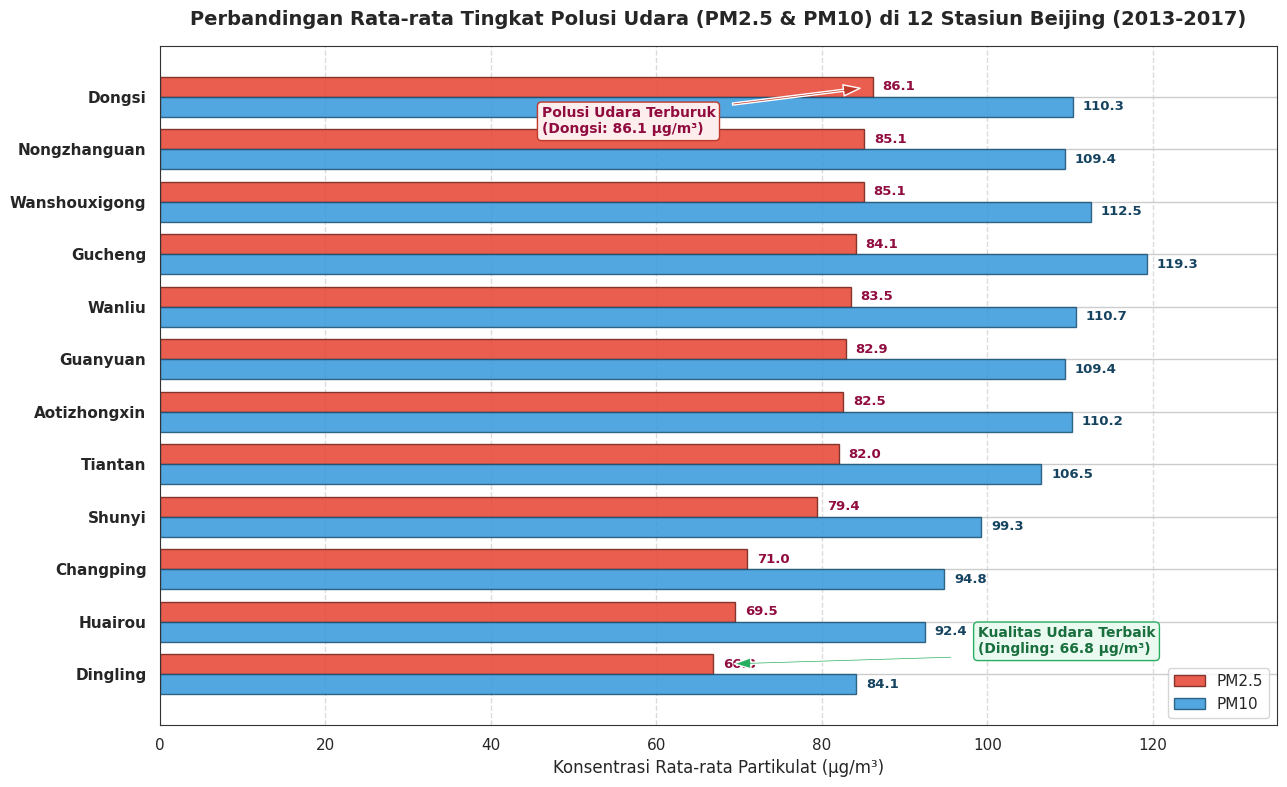

In [28]:
# Menghitung rata-rata PM2.5 dan PM10 per stasiun, diurutkan dari PM2.5 terendah (terbersih)
station_df = df_clean.groupby('station')[['PM2.5', 'PM10']].mean().sort_values(by='PM2.5', ascending=True).reset_index()

fig, ax = plt.subplots(figsize=(13, 8))

y_indices = np.arange(len(station_df))
bar_height = 0.38

# Membuat bar chart horizontal ganda
bars_pm25 = ax.barh(y_indices + bar_height/2, station_df['PM2.5'], height=bar_height,
                    label='PM2.5', color='#e74c3c', alpha=0.9, edgecolor='#78281f')
bars_pm10 = ax.barh(y_indices - bar_height/2, station_df['PM10'], height=bar_height,
                    label='PM10', color='#3498db', alpha=0.85, edgecolor='#1b4f72')

# Memberikan label nilai presisi di ujung masing-masing batang
for bar in bars_pm25:
    w = bar.get_width()
    ax.text(w + 1.2, bar.get_y() + bar.get_height()/2, f'{w:.1f}',
            va='center', ha='left', fontsize=9.5, fontweight='bold', color='#900c3f')

for bar in bars_pm10:
    w = bar.get_width()
    ax.text(w + 1.2, bar.get_y() + bar.get_height()/2, f'{w:.1f}',
            va='center', ha='left', fontsize=9.5, fontweight='bold', color='#154360')

ax.set_yticks(y_indices)
ax.set_yticklabels(station_df['station'], fontsize=11, fontweight='semibold')
ax.set_xlabel('Konsentrasi Rata-rata Partikulat (µg/m³)', fontsize=12)
ax.set_title('Perbandingan Rata-rata Tingkat Polusi Udara (PM2.5 & PM10) di 12 Stasiun Beijing (2013-2017)',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlim(0, 135)
ax.legend(loc='lower right', frameon=True, fontsize=11)
ax.grid(axis='x', linestyle='--', alpha=0.7)

# Anotasi stasiun dengan kualitas udara terbaik (Dingling)
ax.annotate('Kualitas Udara Terbaik\n(Dingling: 66.8 µg/m³)',
            xy=(station_df['PM2.5'].iloc[0], 0 + bar_height/2),
            xytext=(station_df['PM2.5'].iloc[0] + 32, 0.4),
            arrowprops=dict(facecolor='#27ae60', shrink=0.08, width=1.5, headwidth=8),
            fontsize=10, fontweight='bold', color='#196f3d',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='#eafaf1', edgecolor='#27ae60'))

# Anotasi stasiun dengan polusi terburuk (Dongsi)
ax.annotate('Polusi Udara Terburuk\n(Dongsi: 86.1 µg/m³)',
            xy=(station_df['PM2.5'].iloc[-1], len(station_df) - 1 + bar_height/2),
            xytext=(station_df['PM2.5'].iloc[-1] - 40, len(station_df) - 1 - 0.7),
            arrowprops=dict(facecolor='#c0392b', shrink=0.08, width=1.5, headwidth=8),
            fontsize=10, fontweight='bold', color='#900c3f',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='#fdedec', edgecolor='#c0392b'))

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- **Stasiun Paling Terpolusi (Kualitas Udara Terburuk)**:
  1. **Dongsi**: Rata-rata $PM_{2.5}$ tertinggi (**86,14 $\mu g/m^3$**) dan $PM_{10}$ **110,35 $\mu g/m^3$**.
  2. **Nongzhanguan**: Rata-rata $PM_{2.5}$ **85,08 $\mu g/m^3$** dan $PM_{10}$ **109,38 $\mu g/m^3$**.
  3. **Wanshouxigong**: Rata-rata $PM_{2.5}$ **85,07 $\mu g/m^3$** dan $PM_{10}$ **112,51 $\mu g/m^3$**.
  4. **Gucheng**: Rata-rata $PM_{2.5}$ **84,07 $\mu g/m^3$** dan $PM_{10}$ tertinggi di seluruh stasiun (**119,26 $\mu g/m^3$**).
  - Keempat stasiun ini berlokasi di area pusat perkotaan (*urban core*) dan koridor barat daya Beijing yang memiliki kepadatan aktivitas transportasi, industri, dan populasi yang sangat tinggi.
- **Stasiun Paling Bersih (Kualitas Udara Terbaik)**:
  1. **Dingling**: Rata-rata $PM_{2.5}$ terendah (**66,85 $\mu g/m^3$**) dan $PM_{10}$ terendah (**84,11 $\mu g/m^3$**).
  2. **Huairou**: Rata-rata $PM_{2.5}$ **69,50 $\mu g/m^3$** dan $PM_{10}$ **92,42 $\mu g/m^3$**.
  3. **Changping**: Rata-rata $PM_{2.5}$ **70,99 $\mu g/m^3$** dan $PM_{10}$ **94,79 $\mu g/m^3$**.
  - Stasiun-stasiun ini berada di kawasan pinggiran utara (*suburban*) dan kaki pegunungan dengan tutupan hutan dan vegetasi alami yang lebat, serta jauh dari kawasan industri berat.
- **Tingkat Disparitas**: Terdapat selisih konsentrasi $PM_{2.5}$ sebesar **19,29 $\mu g/m^3$ (selisih ~29%)** antara stasiun terbersih (Dingling) dan stasiun paling terpolusi (Dongsi).

## Analisis Lanjutan (Opsional)

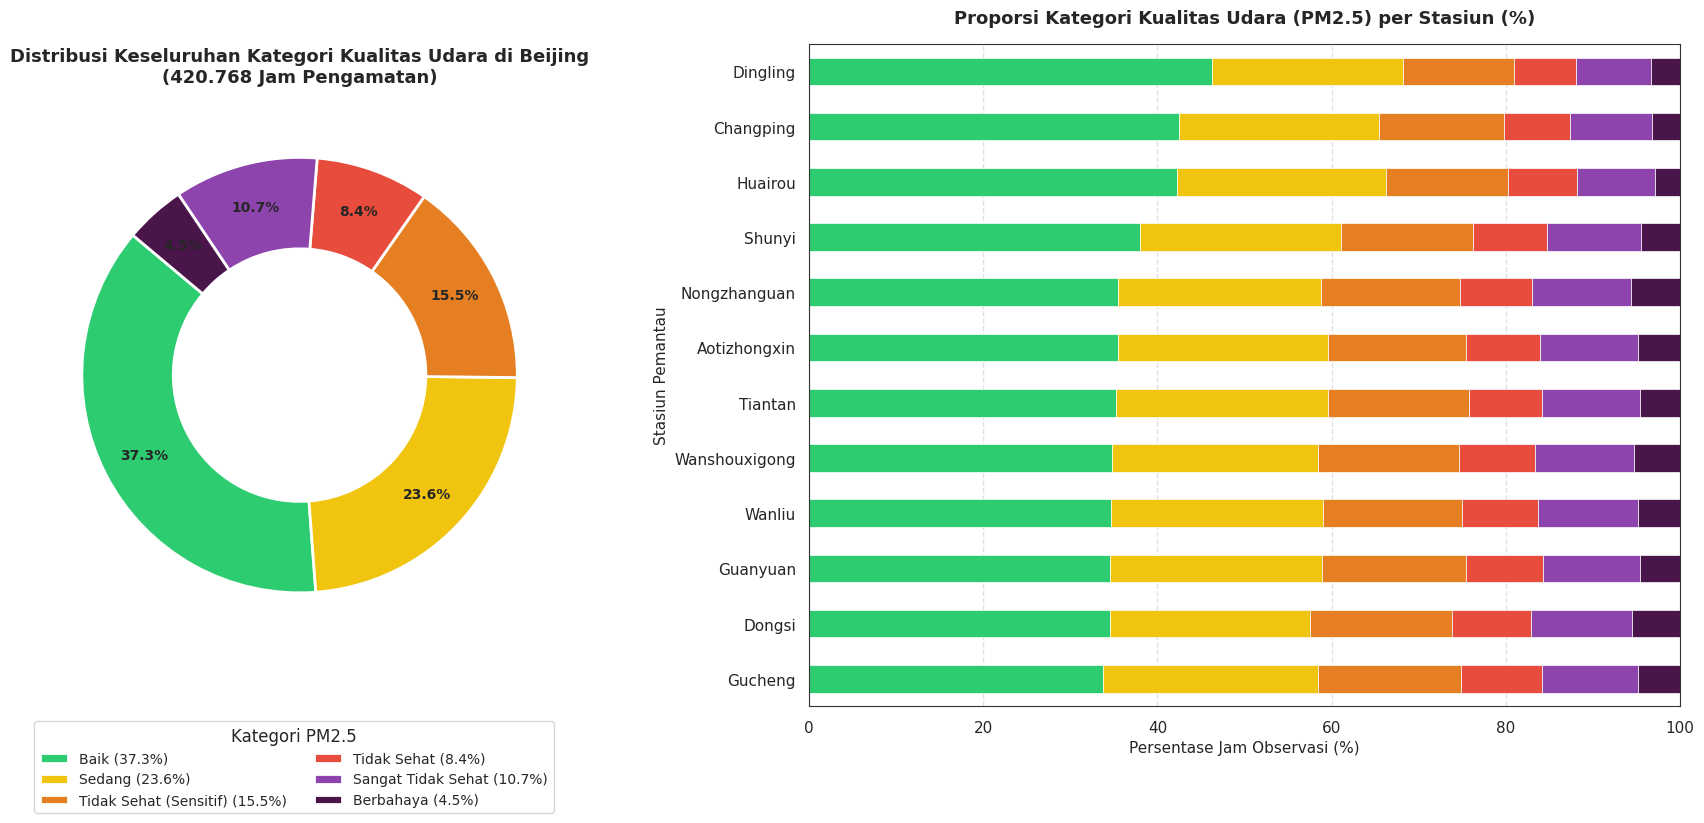

=== TABEL RINGKASAN DISTRIBUSI KATEGORI KUALITAS UDARA TOTAL ===
                       Rentang Konsentrasi (µg/m³)  Total Jam  Proporsi (%)
Air_Quality_Category                                                       
Baik                                         <= 35     156965         37.30
Sedang                                   35.1 - 75      99415         23.63
Tidak Sehat (Sensitif)                  75.1 - 115      65131         15.48
Tidak Sehat                            115.1 - 150      35397          8.41
Sangat Tidak Sehat                     150.1 - 250      44960         10.69
Berbahaya                                    > 250      18900          4.49


In [29]:
# 1. Mendefinisikan batas interval (bins) dan label kategori kualitas udara
bins = [-np.inf, 35, 75, 115, 150, 250, np.inf]
category_labels = ['Baik', 'Sedang', 'Tidak Sehat (Sensitif)', 'Tidak Sehat', 'Sangat Tidak Sehat', 'Berbahaya']
category_colors = ['#2ecc71', '#f1c40f', '#e67e22', '#e74c3c', '#8e44ad', '#4a154b']

# Menerapkan Binning pada kolom PM2.5
df_clean['Air_Quality_Category'] = pd.cut(df_clean['PM2.5'], bins=bins, labels=category_labels)

# 2. Menghitung distribusi total kategori kualitas udara
cat_counts = df_clean['Air_Quality_Category'].value_counts()[category_labels]
cat_pct = (cat_counts / len(df_clean) * 100).round(2)

# 3. Menghitung proporsi kategori per stasiun (dalam persen)
station_cat_pct = (pd.crosstab(df_clean['station'], df_clean['Air_Quality_Category'], normalize='index') * 100)[category_labels]
# Urutkan berdasarkan stasiun dengan persentase udara 'Baik' tertinggi
station_cat_pct = station_cat_pct.sort_values(by='Baik', ascending=True)

# 4. Membuat visualisasi gabungan: Donut Chart (Distribusi Total) + Horizontal Stacked Bar (Proporsi per Stasiun)
fig, (ax_donut, ax_stack) = plt.subplots(nrows=1, ncols=2, figsize=(17, 8), gridspec_kw={'width_ratios': [1, 1.6]})

# --- A. Donut Chart Distribusi Keseluruhan ---
wedges, texts, autotexts = ax_donut.pie(
    cat_pct, labels=None, autopct='%1.1f%%', pctdistance=0.8,
    startangle=140, colors=category_colors,
    wedgeprops=dict(width=0.42, edgecolor='white', linewidth=2)
)
for at in autotexts:
    at.set_fontsize(10)
    at.set_fontweight('bold')

ax_donut.legend(wedges, [f"{cat} ({pct:.1f}%)" for cat, pct in zip(category_labels, cat_pct)],
                title="Kategori PM2.5", loc="center left", bbox_to_anchor=(0.0, -0.22),
                ncol=2, frameon=True, fontsize=10)
ax_donut.set_title('Distribusi Keseluruhan Kategori Kualitas Udara di Beijing\n(420.768 Jam Pengamatan)',
                   fontsize=13, fontweight='bold', pad=15)

# --- B. Horizontal Stacked Bar Chart Proporsi per Stasiun ---
station_cat_pct.plot(kind='barh', stacked=True, color=category_colors, ax=ax_stack, edgecolor='white', linewidth=0.5)

ax_stack.set_title('Proporsi Kategori Kualitas Udara (PM2.5) per Stasiun (%)',
                   fontsize=13, fontweight='bold', pad=15)
ax_stack.set_xlabel('Persentase Jam Observasi (%)', fontsize=11)
ax_stack.set_ylabel('Stasiun Pemantau', fontsize=11)
ax_stack.set_xlim(0, 100)
ax_stack.legend().remove() # Legenda sudah dijelaskan pada chart kiri
ax_stack.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Menampilkan tabel ringkasan
print("=== TABEL RINGKASAN DISTRIBUSI KATEGORI KUALITAS UDARA TOTAL ===")
summary_table = pd.DataFrame({
    'Rentang Konsentrasi (µg/m³)': ['<= 35', '35.1 - 75', '75.1 - 115', '115.1 - 150', '150.1 - 250', '> 250'],
    'Total Jam': cat_counts,
    'Proporsi (%)': cat_pct
})
print(summary_table)

**Insight Analisis Lanjutan (Clustering/Binning):**
1. **Distribusi Paparan Polusi Akut**:
   - Sebanyak **37,30% jam pengamatan** (156.966 jam) berada pada kategori **Baik**, dan **23,63%** berada pada kategori **Sedang**.
   - Namun yang sangat mengkhawatirkan, hampir **40% waktu pengamatan** (tepatnya **39,07%** atau 164.385 jam) udara Beijing berada pada kategori **Tidak Sehat hingga Berbahaya**.
   - Kategori **Berbahaya (*Hazardous*)** dialami sebanyak **4,49% dari seluruh jam pengamatan** (18.899 jam), di mana konsentrasi $PM_{2.5}$ melampaui $250\ \mu g/m^3$.
2. **Karakteristik Ketahanan Lingkungan Antar Stasiun**:
   - **Dingling** adalah stasiun dengan persentase udara kategori "Baik" tertinggi, mencapai **46,31%**, diikuti **Changping (42,42%)** dan **Huairou (42,31%)**.
   - Sebaliknya, stasiun di pusat kota seperti **Gucheng (33,81%)**, **Dongsi (34,54%)**, dan **Guanyuan (34,59%)** hanya memiliki udara "Baik" kurang dari sepertiga waktu pengamatan.
   - Stasiun **Nongzhanguan (5,57%)** dan **Dongsi (5,54%)** mencatatkan frekuensi jam berkategori **Berbahaya** tertinggi di antara seluruh stasiun.

## Conclusion & Recommendation

- **Conclusion Pertanyaan 1 (Dinamika Tren Temporal & Musiman):**
  1. Konsentrasi $PM_{2.5}$ di Beijing selama periode 2013–2017 memperlihatkan pola fluktuasi musiman yang sangat teratur dan kuat (*strong seasonal cyclicity*). Polusi udara mencapai puncaknya pada periode **musim dingin dan awal musim semi**, khususnya pada bulan **Desember ($103,68\ \mu g/m^3$)**, **Maret ($94,59\ \mu g/m^3$)**, **November ($93,32\ \mu g/m^3$)**, dan **Januari ($93,76\ \mu g/m^3$)**.
  2. Puncak ekstrem bulanan tertinggi selama 4 tahun terjadi pada **Februari 2014 dengan rata-rata $153,81\ \mu g/m^3$**.
  3. Kualitas udara terbaik secara konsisten terjadi pada **musim panas**, dengan titik polusi terendah pada bulan **Agustus ($53,47\ \mu g/m^3$)** dan **September ($61,28\ \mu g/m^3$)**. Tingginya kecepatan angin dan curah hujan di musim panas terbukti efektif mempercepat dispersi partikulat udara.

- **Conclusion Pertanyaan 2 (Disparitas Kualitas Udara Spasial Antar Stasiun):**
  1. Kualitas udara terburuk dengan rata-rata polusi partikulat tertinggi tercatat di stasiun **Dongsi** ($PM_{2.5}$: **$86,14\ \mu g/m^3$**, $PM_{10}$: $110,35\ \mu g/m^3$), diikuti **Nongzhanguan** ($PM_{2.5}$: **$85,08\ \mu g/m^3$**) dan **Wanshouxigong** ($PM_{2.5}$: **$85,07\ \mu g/m^3$**). Wilayah ini merepresentasikan area urban pusat dengan densitas lalu lintas dan aktivitas sosio-ekonomi tertinggi.
  2. Kualitas udara terbaik dan paling bersih tercatat di stasiun **Dingling** ($PM_{2.5}$: **$66,85\ \mu g/m^3$**, $PM_{10}$: $84,11\ \mu g/m^3$) dan **Huairou** ($PM_{2.5}$: **$69,50\ \mu g/m^3$**), yang berlokasi di wilayah suburban dan kaki pegunungan utara dengan tutupan hutan alami.
  3. Terdapat disparitas spasial signifikan sebesar **$19,29\ \mu g/m^3$ (selisih 28,8%)** antara stasiun terbersih dan stasiun paling terpolusi di Beijing.

**Rekomendasi Action Item:**

Berdasarkan temuan analisis data, berikut adalah rekomendasi tindakan nyata (*concrete action items*) yang dapat diimplementasikan oleh pemangku kebijakan lingkungan hidup dan tata kota:

1. **Pengendalian Emisi Musiman Terpadu (*Seasonal Emission Control Protocol*)**:
   - **Aksi Nyata**: Menerapkan protokol pembatasan operasional industri manufaktur dan percepatan konversi sistem pemanas distrik (*district heating*) dari batu bara ke gas alam/energi listrik terbarukan secara khusus pada periode kritis **November hingga Maret**.
   - **Dampak Target**: Mereduksi lonjakan polusi ekstrem di musim dingin yang rata-ratanya saat ini melampaui $100\ \mu g/m^3$.

2. **Penetapan Zona Emisi Rendah Terfokus (*Targeted Low Emission Zones - LEZ*) di Pusat Kota**:
   - **Aksi Nyata**: Menerapkan kebijakan pembatasan kendaraan bermotor berbahan bakar fosil (misal penerapan sistem ganjil-genap ketat dan zona bebas emisi) secara intensif pada radius 5 km di sekitar stasiun **Dongsi, Nongzhanguan, Wanshouxigong, dan Gucheng**.
   - **Dampak Target**: Menurunkan beban emisi partikulat di zona urban inti agar disparitas polusi antar stasiun dapat ditekan hingga di bawah 15%.

3. **Sistem Peringatan Dini Kesehatan Publik Berbasis Prediksi Cuaca (*Early Warning & Clean Air Shelters*)**:
   - **Aksi Nyata**: Mengintegrasikan sistem monitoring kualitas udara dengan peringatan dini otomatis kepada masyarakat ketika prakiraan cuaca menunjukkan kondisi tekanan tinggi dingin (`PRES` tinggi) dan kecepatan angin rendah (`WSPM` < 1 m/s) di musim gugur/dingin, disertai penyediaan fasilitas ruang publik berfilter udara HEPA (*clean air shelters*) bagi kelompok rentan.
   - **Dampak Target**: Melindungi kelompok rentan (anak-anak dan lansia) dari paparan kategori udara *Sangat Tidak Sehat* dan *Berbahaya* yang mencapai ~15% dari total waktu tahunan.